# CX-101 Cellular Assay — Development of a Data Processing and Analysis Pipeline 

Fictional experiment:
A concentration-response experiment investigating the effect of a fictional compound on intracellular calcium levels in cultured human muscle cells.
A newly identified compound is being investigated for its effect on intracellular calcium concentration in cultured human muscle cells.

The lab performs a concentration-response experiment.


* Compound: CX-101 (fictional)
* Cell type: cultured human skeletal muscle cells
* Concentrations: 0, 0.1, 1, 10, 100 nM, 1 µM
* Several biological/technical replicates
* Negative control: vehicle-treated cells
* Positive control: something known to induce a calcium response
* Measurement: intracellular calcium signal

Q: Does exposure to CX-101 produce a concentration-dependent change in intracellular calcium, and how reliable is the resulting dataset?


Pipeline:
Validation → cleaning → QC → statistical analysis → visualization → automated PDF report.

Input:
Messy Excel/CSV files containing experimental measurements, controls and replicates.

Output:
A reproducible analysis package plus a professional scientific report.


**For now, this notebook serves the development of the general framework for data cleaning and QC.**

## modules

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, re
from pathlib import Path
%matplotlib inline

## Input

In [2]:
data_path = "../data/"

In [3]:
# --------------------------------------------------------------------------- #
# Name / unit mappings
# --------------------------------------------------------------------------- #
# Keys are compared after normalisation (strip, lower-case, spaces/hyphens -> "_").
COLUMN_MAPPING = {
    "experiment_date": "date",
    "batch_id": "batch",
    "plate": "plate_id",
    "well_position": "well",
    "compound_name": "compound",
    "conc": "concentration",
    "concentration_unit": "unit",
    "replicate_id": "replicate",
    "rep": "replicate",
    "response_rfu": "rfu",
}

# Keys: lower-case, all non-alphanumerics removed ("CX-101", "cx 101" -> "cx101").
COMPOUND_MAPPING = {
    "cx101": "CX-101",
    "vehicle": "Vehicle",
    "ionomycin": "Ionomycin",
}

# Keys: lower-case; both micro sign (U+00B5) and Greek mu (U+03BC) are replaced by "u".
UNIT_MAPPING = {"nm": "nM", "um": "µM"}
UNIT_TO_NM = {"nM": 1.0, "µM": 1000.0}

REQUIRED_COLUMNS = (
    "batch", "plate_id", "well", "compound", "concentration", "unit", "replicate", "rfu",
)

LOG_COLUMNS = ["source_file", "source_row", "field", "change_type",
               "old_value", "new_value"]
CANONICAL_ORDER = ["source_file", "source_row", "date", "plate_id", "well",
                   "replicate", "compound", "concentration", "unit", "rfu", "notes",
                   "concentration_raw", "unit_raw"]

In [4]:
def _fmt(x) -> str:
    if x is None or pd.isna(x):
        return "<missing>"
    #float instead of np.floating would be fine for the data here
    return f"{x:g}" if isinstance(x, (float, np.floating)) else str(x)


def normalize_column_names(columns) -> list[str]:
    return [re.sub(r"[\s\-]+", "_", str(c).strip().lower()) for c in columns]
    
# eventually turn this into a class 
def standardize_data(raw_batch: pd.DataFrame , source_file: str):

    def _apply(df, col, new, change_type, log):
        old = df[col].copy()
        # recording the exact changes
        o, n = old.map(_fmt), new.map(_fmt)
        changed = o.ne(n)
        # changes that only remove leading/trailing blanks are invisible in a log: say so
        trimmed = changed & o.str.strip().eq(n)
        # all the changes excluding white space trimming
        other = changed & ~trimmed
        # after recording the changes replace col in df with new adapted entry
        df[col] = new
        _log(df, other, col, change_type, o, n, log)
        _log(df, trimmed, col, "whitespace_trimmed", "'" + o + "'", "'" + n + "'", log)


    def _log(df, mask, field, change_type, old, new, log):
        for idx in df.index[mask.fillna(False)]:
            log.append(dict(source_file=df.at[idx, "source_file"],# batch=df.at[idx, "batch"],
                            source_row=int(df.at[idx, "source_row"]), field=field,
                            change_type=change_type, old_value=old.at[idx],
                            new_value=new.at[idx]))

        
    df = raw_batch.copy()   
    log: list[dict] = []   

    # preserve the input row identifier and source file before concatenating
    df["source_file"] = source_file
    df["source_row"] = np.arange(len(df)) + 2 # make sure it matches the indexing schema used in Excel
    
    # columns
    original_columns = list(raw_batch.columns)
    # standardize names and map them to the canonical schema
    df.columns = (
        df.columns.str.strip().str.lower().str.replace(" ", "_")
    )
    df = df.rename(columns=COLUMN_MAPPING)
        
    # mapped = [COLUMN_MAPPING.get(n, n) for n in normalize_column_names(original_columns)]
    # df.columns = mapped  + ["source_file", "source_row"]
    
    for old, new in zip(original_columns, df.columns):
        if old != new:
            log.append(dict(
                source_file=source_file,
                source_row=None,
                field="column_name",
                change_type="column_renaming",
                old_value=str(old),
                new_value=new,
            ))
            
    df["batch"] = pd.to_numeric(df["batch"], errors="coerce").astype("Int64")
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    
    # identifiers 
    # add for completeness
    plate_id = df["plate_id"].astype("string").str.strip().str.upper()
    _apply(df, "plate_id", plate_id, "identifier_standardization", log)
    well = df["well"].astype("string").str.strip().str.upper()
    _apply(df, "well", well, "identifier_standardization", log)
    rep = pd.to_numeric(df["replicate"], errors="coerce").round().astype("Int64")
    _apply(df, "replicate", rep, "type_standardization", log)

    
    # compound names 
    raw_compound = df["compound"].astype("string")
    key = raw_compound.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    mapped_c = key.map(COMPOUND_MAPPING)
    new_compound = mapped_c.fillna(raw_compound.str.strip())
    _apply(df, "compound", new_compound, "compound_standardization", log)

    
    # concentration + unit -> nM 
    old_conc, old_unit = df["concentration"].copy(), df["unit"].copy()
    df["concentration_raw"], df["unit_raw"] = old_conc, old_unit

    ukey = (old_unit.astype("string").str.strip()
            # be sure to capture both, micro sign and Greek mu, in case this is wrong in xslx file
            .str.replace("µ", "u").str.replace("μ", "u").str.lower())
    canonical = ukey.map(UNIT_MAPPING)
    num = pd.to_numeric(old_conc, errors="coerce")
    factor = pd.to_numeric(canonical.map(UNIT_TO_NM), errors="coerce")
    new_conc = (num * factor).round(9)          

    # map where unit was converted
    converted = new_conc.notna() & (
        old_conc.map(_fmt).ne(new_conc.map(_fmt)) | old_unit.map(_fmt).ne("nM"))
    _log(df, converted, "concentration", "unit_conversion",
              old_conc.map(_fmt) + " " + old_unit.map(_fmt),
              new_conc.map(_fmt) + " nM", log)
    
    # log nan in conc and unit
    bad_num = num.isna() & old_conc.notna()
    _log(df, bad_num, "concentration", "invalid_concentration_set_missing",
              old_conc.map(_fmt), new_conc.map(_fmt), log)
    bad_unit = canonical.isna() & num.notna()
    _log(df, bad_unit, "unit", "invalid_unit_concentration_set_missing",
              old_unit.map(_fmt), pd.Series("<missing>", index=df.index), log)

    df["concentration"] = new_conc
    df["unit"] = pd.Series("nM", index=df.index, dtype="string").where(new_conc.notna())

    
    # measurement 
    # no QC yet, only log what has changed
    rfu = pd.to_numeric(df["rfu"], errors="coerce")
    _log(df, rfu.isna() & df["rfu"].notna(), "rfu", "invalid_rfu_set_missing",
              df["rfu"].map(_fmt), rfu.map(_fmt), log)
    df["rfu"] = rfu

    cols = [c for c in CANONICAL_ORDER if c in df.columns]
    cols += [c for c in df.columns if c not in cols]
    return df[cols], pd.DataFrame(log, columns=LOG_COLUMNS)

In [5]:
def find_batch_files(input_dir, pattern: str = "CX101_batch_*_raw.*") -> list[Path]:
    files = sorted(Path(input_dir).glob(pattern))
    if not files:
        raise FileNotFoundError(f"No files matching {pattern!r} in {input_dir}")
    return files

def read_raw_data(path) -> pd.DataFrame:
    if path.suffix.lower() in (".xlsx", ".xlsm", ".xls"):
        return pd.read_excel(path, sheet_name=0)
    raise ValueError(f"Unsupported file type: {path}")


In [6]:
def standardize_files(files: list[Path]):
    """Read, validate and standardise several raw files into one table + one log."""
    frames, logs = [], []
    for f in files:
        d, lg = standardize_data(read_raw_data(f), source_file=Path(f).name)
        frames.append(d)
        logs.append(lg)
    df = pd.concat(frames, ignore_index=True)
    log = pd.concat(logs, ignore_index=True)
    return df, log

In [7]:
data_files = find_batch_files(data_path)
df, log_df = standardize_files(data_files)

In [8]:
log_df = log_df.copy()

log_df.loc[
    log_df["source_file"].duplicated(),
    "source_file"
] = ""

display(log_df)

log_csv = "../reports/standardization_log.csv"
# log_df.to_csv(log_csv, index=False, na_rep="-")

,source_file,source_row,field,change_type,old_value,new_value
0,CX101_batch_1_raw.xlsx,NaN,column_name,column_renaming,Experiment Date,date
1,,NaN,column_name,column_renaming,Batch,batch
2,,NaN,column_name,column_renaming,Plate ID,plate_id
3,,NaN,column_name,column_renaming,Well,well
4,,NaN,column_name,column_renaming,Compound,compound
5,,NaN,column_name,column_renaming,Concentration,concentration
6,,NaN,column_name,column_renaming,Unit,unit
7,,NaN,column_name,column_renaming,Replicate,replicate
8,,NaN,column_name,column_renaming,RFU,rfu
9,,NaN,column_name,column_renaming,Notes,notes


## QC checks

In [9]:
CHECK_COLUMNS = [
    "batch", "plate_id", "well", "replicate", "compound", "concentration", "unit", "rfu"
]

In [10]:
def QC_checks(df, check_columns=CHECK_COLUMNS):
    duplicates = df[
        df.duplicated(subset=check_columns, keep="first")
    ]
    
    missing_values = df[
        df[check_columns[5:]].isna().any(axis=1)
    ]
    
    
    missing_identifiers = df[
        df[check_columns[:5]].isna().any(axis=1)
    ]
    return duplicates, missing_identifiers, missing_values

# find iqr outliers per condition
def outlier_mask(df, column="rfu", outlier_min_n=6, outlier_min_rel_dev=0.20):
    
    # a statistical outlier must also deviate this much (fraction) from the group median;
    # with 6 wells per group the IQR/MAD rules alone flag tightly clustered, harmless values
   

    group_cols = ["batch", "compound", "concentration"]

    def flag_group(group):
        values = group[column].astype(float)
        flagged = pd.Series(False, index=values.index)
        median = values.median()
        
        # IQR is unstable with very small groups
        if values.notna().sum() < outlier_min_n:
            return flagged

        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        stat = values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)

        relevant = (values - median).abs() >= outlier_min_rel_dev * abs(median)
        
        # return flagged.fillna(False)
        return stat & relevant

    return (
        df.groupby(group_cols, group_keys=False)
          .apply(flag_group)
          .reindex(df.index, fill_value=False)
    )



In [12]:
duplicates, missing_identifiers, missing_values = QC_checks(df)

potential_rfu_outlier = outlier_mask(df)
rfu_outlier_rows = df.loc[potential_rfu_outlier].copy()


## QC Summary


In [13]:
qc_results = [missing_values, duplicates, missing_identifiers, rfu_outlier_rows]

In [14]:
checks = ["Missing values", "Duplicate observations", "Missing identifiers", "Potential RFU outliers"]
actions = ["Flag & exclude from response analysis", "Remove confirmed duplicate", "Flag", "Review"]
incidents = []
rows = []
for i, result in enumerate(qc_results):
    incidents.append(result.__len__())
    _rows = []
    for r in zip(result["batch"], result["source_row"]):

        _rows.append(r)
    rows.append(_rows)

In [15]:
qc_summary = {
    "Check": checks,
    "# Incident": incidents,
    "Batch & Source Row": rows,
    "Action": actions
}


In [16]:
df_qc = pd.DataFrame.from_dict(qc_summary)

In [17]:
df_qc

,Check,# Incident,Batch & Source Row,Action
0,Missing values,1,"[(1, 19)]",Flag & exclude from response analysis
1,Duplicate observations,1,"[(1, 44)]",Remove confirmed duplicate
2,Missing identifiers,1,"[(3, 37)]",Flag
3,Potential RFU outliers,3,"[(2, 32), (3, 26), (3, 43)]",Review


In [18]:
fn_qc_summary = "../reports/qc_summary.csv"
# df_qc.to_csv(fn_qc_summary, index=False)

### dev: combined QC check and summary 

not finished

In [19]:

# --------------------------------------------------------------------------- #
# QC checks: flag name -> (label, excluded from analysis by default, description)
# --------------------------------------------------------------------------- #
QC_CHECKS = {
    "missing_identifier": (
        "Missing identifier", True,
        "batch, plate, well or compound is missing"),
    "missing_replicate_id": (
        "Missing replicate ID", False,
        "replicate number is missing (well position still identifies the observation)"),
    "missing_rfu": (
        "Missing RFU", True,
        "no measured signal"),
    "invalid_concentration": (
        "Invalid concentration/unit", True,
        "concentration or unit missing, non-numeric or unit not recognised"),
    "unknown_compound": (
        "Unknown compound", True,
        "compound name not in the list of known compounds after standardisation"),
    "exact_duplicate": (
        "Exact duplicate", True,
        "identical record already present (extra copy removed, first occurrence kept)"),
    "conflicting_duplicate": (
        "Conflicting duplicate", True,
        "same batch/plate/well appears more than once with different content"),
    # "layout_mismatch": (
    #     "Plate-layout mismatch", True,
    #     "compound or concentration differs from the expected plate layout for this well"),
    "rfu_outlier": (
        "Potential RFU outlier", True,
        "outside the outlier rule within its batch x compound x concentration group"),
}
# --------------------------------------------------------------------------- #
# hard checks - strict data check-upa, exclude checks that depend on interpretation
# --------------------------------------------------------------------------- #
HARD_CHECKS = [k for k in QC_CHECKS if k != "rfu_outlier"]

In [20]:
d = df.copy()
known = ("Vehicle", "Ionomycin", "CX-101")

# completeness - check entries for nan
d["missing_identifier"] = d[["batch", "plate_id", "well", "compound"]].isna().any(axis=1)
d["missing_replicate_id"] = d["replicate"].isna()
d["missing_rfu"] = d["rfu"].isna()
d["invalid_concentration"] = d["concentration"].isna() | d["unit"].isna()
d["unknown_compound"] = d["compound"].notna() & ~d["compound"].isin(known)


# check for duplicates
record = ["batch", "plate_id", "well", "replicate", "compound", "concentration", "rfu"]
d["exact_duplicate"] = d.duplicated(subset=record, keep="first")
# not present in fictional data but for completeness lets also implement this check
d["conflicting_duplicate"] = False
cand = d.loc[~d["exact_duplicate"] & d[["batch", "plate_id", "well"]].notna().all(axis=1)]
dup_idx = cand.index[cand.duplicated(subset=["batch", "plate_id", "well"], keep=False)]
d.loc[dup_idx, "conflicting_duplicate"] = True

# outliers, atm the method used for identifying potential outliers is by calculating iqr - add other  later
exclusion: dict = {k: v[1] for k, v in QC_CHECKS.items()}
hard_excl = pd.Series(False, index=d.index)
for k in HARD_CHECKS:
    if exclusion.get(k, False):
        # filterthose out that are flagged for excl
        hard_excl |= d[k]
d["rfu_outlier"] = False
eligible = d[~hard_excl]
_potential_rfu_outlier = outlier_mask(eligible)
# only retrieve the once that are flagged True
d.loc[_potential_rfu_outlier[_potential_rfu_outlier].index, "rfu_outlier"] = True


# add exclusion decision 
def reasons(row):
    return ";".join(k for k in QC_CHECKS if row[k] and exclusion.get(k, False))
d["exclusion_reasons"] = d.apply(reasons, axis=1)
d["exclude"] = d["exclusion_reasons"].ne("")

## Analysis

In [21]:
# exclude potential rfu outliers from analysis
exclude_rfu_outliers = True
if exclude_rfu_outliers:
    df_excl_outliers = df[~potential_rfu_outlier]
    analysis_df = df_excl_outliers.drop_duplicates(subset=CHECK_COLUMNS, keep="first").copy()
else:
    analysis_df = df.drop_duplicates(subset=CHECK_COLUMNS, keep="first").copy()

analysis_df = analysis_df.dropna(subset=["rfu"]).copy()


print("Raw df:", len(df))
print("Analysis df - trimmed:", len(analysis_df))
print("Excluded from analysis:", len(df) - len(analysis_df))

Raw df: 127
Analysis df - trimmed: 122
Excluded from analysis: 5


### descriptive statistics

In [22]:
summary = (analysis_df.groupby(["compound", "concentration"], dropna=False)["rfu"]
           .agg(n="count", mean="mean", std="std")
           .reset_index()
          )

# add standard error of the mean and coefficient of variation
summary["sem"] = summary["std"] / np.sqrt(summary["n"])
summary["cv_percent"] = summary["std"] / summary["mean"] * 100

display(summary)

,compound,concentration,n,mean,std,sem,cv_percent
0,CX-101,0.1,17,114.518235,8.266103,2.004825,7.218155
1,CX-101,1.0,18,133.872222,7.355910,1.733805,5.494725
2,CX-101,10.0,17,170.085882,8.623387,2.091479,5.070019
3,CX-101,100.0,17,217.284706,10.001618,2.425749,4.603001
4,CX-101,1000.0,19,239.846316,12.685773,2.910316,5.289125
5,Ionomycin,1000.0,16,247.356875,9.367071,2.341768,3.786865
6,Vehicle,0.0,18,99.401667,6.395089,1.507337,6.433584


### Visualise

First normalize to  vehicle -> account for background noise

For an exploratory visualization:

**response (% vehicle) = RFU / mean vehicle RFU × 100**



In [23]:
vehicle_mean = (summary.loc[summary["compound"] == "Vehicle", "mean"]).to_numpy()

In [24]:
vehicle_mean = analysis_df.loc[
    analysis_df["compound"].eq("Vehicle"),
    "rfu"
].mean()

In [25]:
analysis_df["response_pct_vehicle"] = analysis_df["rfu"] / vehicle_mean * 100
normalized_summary = (analysis_df.groupby(["compound", "concentration"], dropna=False)["response_pct_vehicle"]
           .agg(n="count", mean="mean", std="std")
           .reset_index()

        )
normalized_summary["sem"] = normalized_summary["std"] / np.sqrt(normalized_summary["n"])
display(normalized_summary)

,compound,concentration,n,mean,std,sem
0,CX-101,0.1,17,115.207561,8.315860,2.016892
1,CX-101,1.0,18,134.678046,7.400188,1.744241
2,CX-101,10.0,17,171.109689,8.675294,2.104068
3,CX-101,100.0,17,218.592618,10.061821,2.440350
4,CX-101,1000.0,19,241.290034,12.762133,2.927834
5,Ionomycin,1000.0,16,248.845802,9.423455,2.355864
6,Vehicle,0.0,18,100.000000,6.433584,1.516410


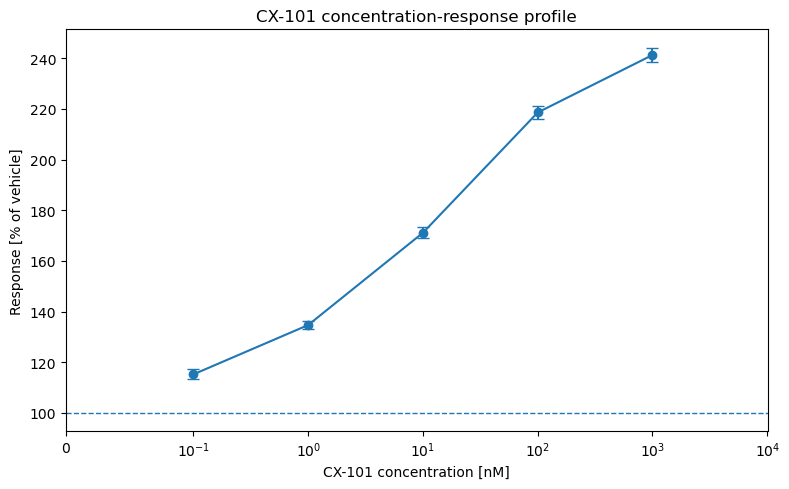

In [26]:
cx = normalized_summary[
    normalized_summary["compound"].eq("CX-101")
].sort_values("concentration")

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    cx["concentration"],
    cx["mean"],
    yerr=cx["sem"],
    marker="o",
    linestyle="-",
    capsize=4,
)
ax.axhline(100, linestyle="--", linewidth=1)
ax.set_xscale("symlog", linthresh=0.1)
ax.set(xlabel="CX-101 concentration [nM]", ylabel="Response [% of vehicle]", xlim=(0, 10100))
ax.set_title("CX-101 concentration-response profile")
plt.tight_layout()
# plt.show()
# fig_name = "cx-101_conc-respoxscale("symlog", linthresh=0.1))

### Batch-level consistency

In [27]:
batch_summary = (
    analysis_df
    .groupby(["batch", "compound", "concentration"])["rfu"]
    .agg(n="count", mean="mean", std="std")
    .reset_index()
)

batch_summary["cv_percent"] = (
    batch_summary["std"] / batch_summary["mean"] * 100
)


display(batch_summary)


,batch,compound,concentration,n,mean,std,cv_percent
0,1,CX-101,0.1,5,116.900000,6.511939,5.570521
1,1,CX-101,1.0,6,135.808333,6.509551,4.793190
2,1,CX-101,10.0,6,174.416667,3.873188,2.220653
3,1,CX-101,100.0,6,217.693333,10.307763,4.734993
4,1,CX-101,1000.0,7,239.604286,7.504503,3.132040
5,1,Ionomycin,1000.0,5,251.232000,7.324416,2.915399
6,1,Vehicle,0.0,6,97.316667,8.425705,8.658029
7,2,CX-101,0.1,6,110.523333,8.652435,7.828605
8,2,CX-101,1.0,6,129.246667,8.479332,6.560581
9,2,CX-101,10.0,6,162.225000,6.894295,4.249835


In [28]:
batch_summary[batch_summary['compound'] == 'CX-101'][batch_summary["concentration"] == 1000.0]

/var/folders/dh/r7h1rkd977v2zqb15q4h1dnr0000gp/T/ipykernel_20064/3788042309.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  batch_summary[batch_summary['compound'] == 'CX-101'][batch_summary["concentration"] == 1000.0]


,batch,compound,concentration,n,mean,std,cv_percent
4,1,CX-101,1000.0,7,239.604286,7.504503,3.132040
11,2,CX-101,1000.0,6,227.205000,4.665545,2.053452
18,3,CX-101,1000.0,6,252.770000,9.885545,3.910885


## Preliminary assessment

The pipeline can now distinguish:

- **standardization:** mechanical, traceable transformations
- **potential outliers:** observations requiring review rather than automatic deletion.
- **QC findings:** problems detected in the data
- **analysis exclusions:** observations that cannot contribute to the chosen analysis


In [29]:
assessment = []

if len(missing_values):
    assessment.append(f"{len(missing_values)} rows contain missing rfu values.")
if len(duplicates):
    assessment.append(f"{len(duplicates)} rows are involved in duplicate groups.")
if len(missing_identifiers):
    assessment.append(f"{len(missing_identifiers)} rows have missing identifiers.")
if len(rfu_outlier_rows):
    assessment.append(f"{len(rfu_outlier_rows)} potential RFU outlier(s) was (were) flagged by the IQR rule.")
else:
    assessment.append("No potential RFU outliers were flagged by the IQR rule.")

for message in assessment:
    print("•", message)


• 1 rows contain missing rfu values.
• 1 rows are involved in duplicate groups.
• 1 rows have missing identifiers.
• 3 potential RFU outlier(s) was (were) flagged by the IQR rule.


TODO

- fine tune analysis
    - condition specific QC filters
    - appropriate inferential statistics
    - better batch-effect assessment
- automated (PDF) report generation